### **Student Information**
GitHub ID:Evelyn8852

Kaggle name:applechen0705

Kaggle private scoreboard snapshot: 

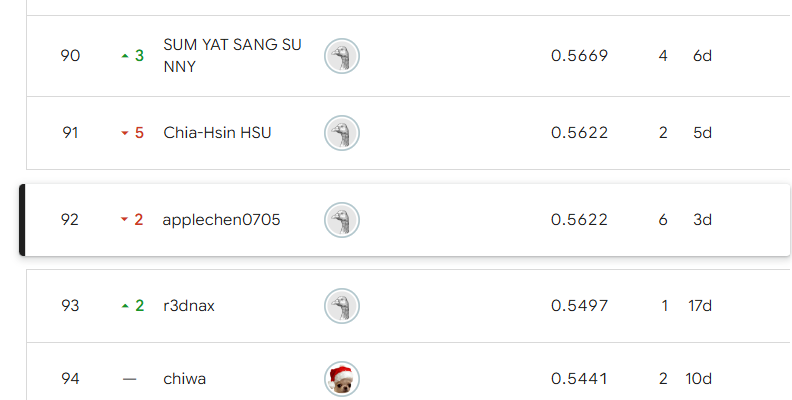

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

## 1. Model Development (10 pts Required)

### 1.1 Preprocessing Steps

將貼文分類為 `anger`、`disgust`、`fear`、`joy`、`sadness`、`surprise` 六種情緒。
使用競賽提供的四個檔案：

| 檔案 | 用途 | 已儲存輸出筆數 |
|---|---|---:|
| `final_posts.json` | 貼文 ID 與原始文字 | 4,800 |
| `data_identification.csv` | 官方 train/test | 4,800 |
| `emotion.csv` | 訓練資料情緒標籤 | 3,360 |
| `sampleSubmission.csv` | 測試 ID 與提交順序 | 1,440 |

以 `post_id` 一對一合併資料，再依官方 `set` 欄位分出 3,360 筆訓練資料與 1,440 筆測試資料。
合併前後檢查 ID 唯一性、缺值、合法標籤與資料集合對應關係。
測試集的 1,440 筆 label 缺值是因未提供真實答案，不予填補，也不用來訓練。

#### 文字清理與斷詞

保留 `text` 原文，另外建立 `clean` 欄位，依序執行：

1. 轉成小寫。
2. 移除符合既有正則表達式的 URL，包括 `http…`、`www.…` 與 `##url##`。
3. 移除 `@<username>` 與其他使用者提及。
4. 合併連續空白並移除頭尾空白。

**沒有**加入停用詞刪除、詞幹化、詞形還原或新的去重規則，也沒有另外刪除標點或 emoji。
TF-IDF 與自訓練詞向量使用 `clean`；MiniLM 使用 `text` 原文。

NLTK `word_tokenize` 只供資料探索與長度統計；
Word2Vec、Doc2Vec、FastText 用 `text.split()` 空白斷詞。
兩者用途不同，並非共用同一份 tokens。

清理後訓練集有 1 筆空文字，測試集沒有空文字。
保留此筆資料；TF-IDF 可將空文字轉為零向量，平均詞向量函式也有零向量回傳處理。

#### 資料探索與驗證切分

| 情緒 | 訓練筆數 |
|---|---:|
| anger | 674 |
| disgust | 454 |
| fear | 288 |
| joy | 875 |
| sadness | 628 |
| surprise | 441 |

類別分布不均，因此以 **Macro F1** 作為本地主要指標，另外記錄 Accuracy 與各類別 precision、recall、F1。
Macro F1 是六類 F1 的等權平均，能反映小類別表現

使用 `train_test_split(test_size=0.2, random_state=42, stratify=label)`，固定取得 2,688 筆訓練與 672 筆驗證資料，主要實驗共用這份切分。
訓練貼文平均長度約 19.3 個 NLTK tokens，測試約 19.0 個；長文與短文的分布圖保留在程式碼輸出中。

原始檢查顯示訓練集有 50 筆重複文字、測試集有 8 筆重複文字，train/test 有 59 種共同原文，固定 train/validation 有 9 種共同清理文字。
為保留原比較設定，本次整理沒有刪除或重新分組；這些重複可能使驗證偏樂觀，是結果解讀的限制。

### 1.2 Feature Engineering Steps

#### 特徵設計與比較目的

| 特徵 | 實作設定 | 使用方式 |
|---|---|---|
| Word TF-IDF | `min_df=2`；比較 `(1,1)` 與 `(1,2)` n-gram | 保留單字與相鄰詞組；最終採用 unigram + bigram |
| Word2Vec | 100 維、window=5、min_count=2、epochs=30、seed=42、workers=1 | 只在訓練子集學習，再平均句中已知詞向量 |
| Doc2Vec | 100 維、window=5、min_count=2、epochs=30、dm=1 | 訓練文件使用已學得文件向量，驗證文件以 `infer_vector(epochs=30)` 推論 |
| FastText | 100 維、window=5、min_count=2、epochs=30、seed=42、workers=1 | 平均詞向量，利用子詞機制處理詞彙變形 |
| MiniLM | `sentence-transformers/all-MiniLM-L6-v2`，384 維，`normalize_embeddings=True` | 對原文產生固定預訓練語意向量，不進行微調 |
| Character TF-IDF | `char_wb`、3–5 gram、min_df=2、max_features=30000、sublinear_tf=True、float32 | 補充單字內部字元片段，測試拼字與局部形式是否提供額外訊息 |

固定切分下，unigram TF-IDF 有 2,547 個特徵；
unigram + bigram 有 6,018 個，後者稀疏度約 99.74%。
加入 384 維 MiniLM 與字元特徵後，V2 固定切分的總特徵維度為 29,776；
完整資料重訓時詞彙表可能變大，維度不必與驗證實驗相同。

#### 特徵組合

最終表示為：

`hstack([Word TF-IDF, MiniLM, Character TF-IDF × char_weight])`

MiniLM 權重先在 `[0.1, 0.5, 1, 2, 5]` 比較，Word + MiniLM 的最佳驗證結果使用權重 1。
字元實驗保留 MiniLM 權重 1，另外比較字元權重 0.5 與 1.0，並保留無字元的控制組。
各區塊沒有新增整體正規化，沿用原先設定。

#### 避免特徵擬合洩漏

固定驗證實驗中的 TF-IDF 只在 2,688 筆訓練資料 fit，驗證資料只 transform。
五折比較時，每折重新在該折訓練資料 fit Word 與 Character TF-IDF。
MiniLM 固定不微調，因此可先對全部標記原文編碼，再按位置索引取出各折特徵；
並未使用全部標籤訓練語意編碼器。

只有在最終重訓與提交時，才以全部 3,360 筆訓練文字 fit 最終 TF-IDF。
這份完整資料特徵不會切回去作為原本的 80/20 驗證特徵。

### 1.3 Explanation of Your Model

#### 實驗設計

先建立 TF-IDF + Linear SVM baseline，比較單字與詞組，再測試 Naive Bayes、KNN、自訓練詞向量與 MLP。接著加入 MiniLM 語意特徵，最後加入字元 TF-IDF，並以相同特徵比較 Logistic Regression。

| 實驗 | 搜尋／固定設定 |
|---|---|
| TF-IDF + SVM | 2 種 n-gram × C=`[0.1,1,10]` × class_weight=`[None,balanced]`，12 組 |
| Word2Vec／Doc2Vec／FastText + SVM | C=0.1、class_weight=None，固定單一分類器設定 |
| MiniLM + SVM | C=`[0.01,0.1,1,10,100]` × class_weight=`[None,balanced]`，10 組 |
| Word + MiniLM + SVM | MiniLM 權重 `[0.1,0.5,1,2,5]`；C=0.1、class_weight=None |
| Word + Char + MiniLM + SVM | 字元權重 `[0.5,1]` × C=`[0.1,1]` × class_weight=`[None,balanced]`，8 組；另加控制組 |
| MLP | hidden layers=(128,64)、ReLU、Adam、alpha=0.001、batch=32、learning_rate=0.001、max_iter=100、early_stopping=True、validation_fraction=0.1、random_state=42 |
| Logistic Regression | C=`[0.1,1,3,10,30]` × class_weight=`[None,balanced]`；lbfgs、max_iter=3000，10 組 |

MLP 另從訓練子集取內部資料做 early stopping；外部成績仍在共同 672 筆驗證集計算。自訓練詞向量沒有接受與其他方法等量的調參，因此比較只代表已測設定，不代表某種方法永遠較差。

#### 固定 80/20 驗證結果

以下數值採用本次上傳檔的已儲存輸出；Doc2Vec 的本次結果為 0.211311，未沿用更早對話的舊結果。

| 模型／設定 | Accuracy | Macro F1 |
|---|---:|---:|
| Unigram + SVM，C=1、None | 0.511905 | 0.485089 |
| Unigram + Bigram + SVM，C=1、None | 0.502976 | 0.485394 |
| 調參後 Word TF-IDF + SVM，C=0.1、balanced | 0.525298 | 0.505616 |
| Word TF-IDF + Naive Bayes | 0.406250 | 0.297914 |
| Word TF-IDF + KNN | 0.211310 | 0.090839 |
| Word2Vec + SVM | 0.313988 | 0.197530 |
| Doc2Vec + SVM | 0.316964 | 0.211311 |
| FastText + SVM | 0.319940 | 0.194489 |
| Word TF-IDF + MLP | 0.483631 | 0.468575 |
| MiniLM + MLP | 0.534226 | 0.519473 |
| 調參後 MiniLM + SVM，C=0.1、None | 0.552083 | 0.514713 |
| Word + MiniLM + SVM，權重1、C=0.1、None | 0.595238 | 0.565811 |
| **Word + Char + MiniLM + SVM，字元權重1、C=0.1、None** | **0.596726** | **0.570361** |
| 相同三種特徵 + 最佳 Logistic Regression，C=1、None | 0.575893 | 0.552657 |

Word2Vec、Doc2Vec 與 FastText 在目前設定下對 fear 的 F1 均為 0；
僅看 Accuracy 會低估小類別辨識不足的問題。
MiniLM + MLP 的 fear F1 為 0.57，但整體 Macro F1 未超過混合特徵 SVM，因此沒有僅依單一類別表現選擇最終模型。

#### 五折交叉驗證與最終選擇

使用 `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`。
字元實驗先從固定驗證集挑選兩個候選，再與原 Combined 控制組使用相同五折比較。

| 候選 | CV Macro F1 平均 | 標準差 | CV Accuracy 平均 |
|---|---:|---:|---:|
| Word + MiniLM，無字元控制組 | 0.544428 | 0.028487 | 0.573512 |
| Word + Char×0.5 + MiniLM | 0.551619 | 0.020788 | 0.579464 |
| **Word + Char×1.0 + MiniLM** | **0.555668** | **0.020485** | **0.581250** |

三者的 SVM 皆為 C=0.1、class_weight=None。
字元權重 1 的平均 Macro F1 比無字元控制組高 **0.011240**，五折中有四折較高，一折較低。
固定驗證集則由 0.565811 提升至 0.570361，差 **0.004550**。
這支持在目前設定下保留字元特徵，但不表示已證明統計顯著，亦不能將全部 Kaggle 分數變化單獨歸因於字元特徵。

原先另做的五折比較中，C=0.1、None 的純 Word TF-IDF 平均 Macro F1 為 0.440721±0.022878；
此設定不是固定切分調參後最佳的 balanced baseline，故兩者不可直接混稱。

Logistic Regression 只更換後續分類器，沿用勝出特徵與權重。
其最佳驗證 Macro F1 為 0.552657，低於相同特徵的 SVM 0.570361；
對話亦回報該次 Kaggle 分數下降，但未提供確切數字。
因此保留它作為負向實驗，最終採用 SVM，不編造 LR 的 Kaggle 分數。

#### 最終模型與提交檔生成

已儲存的勝出設定為 `char1.0_C0.1_None`：Word TF-IDF（1–2 gram）＋ MiniLM（權重1）＋ Character TF-IDF（3–5 gram、權重1），搭配 `LinearSVC(C=0.1, class_weight=None, random_state=42, max_iter=10000)`。

完整重訓使用全部 **3,360** 筆標記資料，對 **1,440** 筆 Kaggle 測試資料預測。
預測先配回 `post_id`，再以範例提交 ID 為左表對齊順序，改為 `id,label`，檢查 ID 唯一性、合法標籤、缺值與列數，以 `index=False` 輸出並回讀核對。

| 檔名 | 來源與用途 |
|---|---|
| `submission_baseline.csv` | 純 Word TF-IDF + balanced SVM，對照 |
| `submission_combined.csv` | Word TF-IDF + MiniLM + SVM，對照 |
| `submission_v2_selected.csv` | 五折選出的字元混合 SVM，採用版本 |
| `submission_logreg.csv` | Logistic Regression，對照，未採用 |
| `submission_final.csv` | 本次整理新增的最終匯出；直接使用 V2 SVM 的同一批預測，非重新選用 LR |

來源檔證實 V2 相對無字元 Combined 改變 138/1,440 筆預測。
最終匯出 Cell 會另外核對 `submission_final.csv` 與 `submission_v2_selected.csv` 內容一致，並輸出模型設定與 CSV SHA-256 供追溯。

#### Kaggle 結果、限制與反思

Kaggle 分數由 **0.5353** 升至 **0.5618**，增加 **0.0265**。
來源 Notebook 不包含排行榜截圖與提交歷史，因此不將這兩個數字自行標成最終 Private 分數或據此推算作業得分；最終榜別與排名以已完成的 Student Information 及排名截圖為準。

此實驗有兩項主要限制：
第一，相同文字可能跨越訓練與驗證；
第二，候選挑選與後續 CV 使用部分相同資料，這是探索性模型選擇，不是完全獨立的測試。
固定種子與 gensim 的 workers=1 有助重現，但套件、硬體與 Doc2Vec 推論等因素仍可能造成小幅差異。

本次結果顯示，保留可解釋的詞彙特徵並補充語意及字元訊息，比單純增加模型種類更有實證支持。
MPNet、Transformer 微調與模型融合曾在對話中被提出，但本檔沒有實作或驗證，不列為已完成方法。

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI


| 本次可取得對話中的提示詞原文／原文片段 | AI 協助內容 | 實際採用與理由 |
|---|---|---|
| 「讀取此檔案如何讓內容更有條理和架構」 | 檢視 Notebook 結構 | 將資料處理、特徵與模型比較分區，提高可讀性 |
| 「請繼續依照原本的要求，逐一檢查 Notebook 的架構、重複程式碼、模型比較，以及 Submission 是否真正使用改善後的模型」 | 追查特徵與提交來源 | 保留完整重訓及 CSV 路徑，區分 baseline、Combined 與 V2 |
| 「現在是0.5618 提高的依據是什麼 還有辦法讓他再更高嗎？」 | 區分分數提升與因果歸因 | 以實際 holdout／CV 比較支持字元特徵，而非只依 leaderboard 推論 |
| 「還有別的方法能夠提高分數嗎？」 | 討論 MPNet、微調與融合 | 本版未實作，不當作既有成果 |
| 「那如果是用logstic regression呢？」 | 提出線性分類器對照 | 測試 Logistic Regression，未預設其一定優於 SVM |
| 「那你不要改預處理之類的，只改後續模型，請給我程式碼跑跑看結果分數」 | 保持特徵、搜尋 LR 模型參數 | 採用，讓差異集中於分類器；保留失敗實驗 |

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [1]:
# Install the sentence-transformers library
%pip install -q sentence-transformers

Note: you may need to restart the kernel to use updated packages.


C:\Users\applechen\Documents\DM2026Labs\DM2026-Lab2-Exercise\.venv\Scripts\python.exe: No module named pip


In [2]:
# test code for environment setup
# Run this cell first. It imports every library the lab uses and prints four
# version numbers. If it raises an ImportError, fix the environment before
# going further; README.md has the steps.
import os
import random
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# NLTK's tokenizer needs a data file that does not ship inside the package.
# These two downloads run once, then find the local copy and return instantly.
import nltk
nltk.download('punkt', quiet=True)      # NLTK tokenizer models
nltk.download('punkt_tab', quiet=True)  # needed by newer NLTK versions
from nltk.tokenize import word_tokenize

import gensim
import sklearn

# Draw plots inside the notebook, and hide library deprecation notices,
# which are warnings about future versions and not errors in your code.
%matplotlib inline
# 保留警告，以便看見收斂或環境問題。

# One seed for everything random in this notebook (numpy, scikit-learn,
# gensim). Passed as `seed=SEED` / `random_state=SEED` wherever it applies.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print('pandas', pd.__version__, '| numpy', np.__version__,
      '| scikit-learn', sklearn.__version__, '| gensim', gensim.__version__)

pandas 3.0.5 | numpy 2.4.6 | scikit-learn 1.9.0 | gensim 4.4.0


In [3]:
from pathlib import Path
from IPython.display import display

OUTPUT_DIR = Path('/kaggle/working')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
import json

# Set the data folder path
data_path = "/kaggle/input/competitions/2026-dm-lab-2-private-competition/"

# Load text data from JSON
with open(data_path + "final_posts.json", "r", encoding="utf-8") as f:
    posts = json.load(f)

posts_df = pd.DataFrame(posts)

# Load CSV files
identification_df = pd.read_csv(data_path + "data_identification.csv")
emotion_df = pd.read_csv(data_path + "emotion.csv")
submission_df = pd.read_csv(data_path + "sampleSubmission.csv")

# Check dataset sizes
print("Posts:", posts_df.shape)
print("Identification:", identification_df.shape)
print("Emotion:", emotion_df.shape)
print("Submission:", submission_df.shape)

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/competitions/2026-dm-lab-2-private-competition/final_posts.json'

In [ ]:
# 合併前檢查鍵值，避免重複 ID 導致資料列展開。
for name, frame in [('posts', posts_df), ('identification', identification_df),
                    ('emotion', emotion_df), ('sample', submission_df)]:
    assert frame['post_id'].notna().all(), f'{name}: missing ID'
    assert frame['post_id'].is_unique, f'{name}: duplicate ID'
assert set(posts_df['post_id']) == set(identification_df['post_id'])

In [ ]:
### Add the code related to the preprocessing steps in cells inside this section

# The six emotion labels in the Kaggle competition
LABELS = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]

# Combine text data with train/test information
data = posts_df.merge(identification_df, on="post_id", how="left", validate="one_to_one")

# Add emotion labels
data = data.merge(emotion_df, on="post_id", how="left", validate="one_to_one")

# Separate training and test data
train_df = data[data["set"] == "train"].copy()
test_df = data[data["set"] == "test"].copy()

# Check the dataset sizes
print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

# Show the first five training examples
train_df.head()

In [ ]:
# Check training and test data
for name, df in {"train": train_df, "test": test_df}.items():

    print(f"--- {name} ---")

    # 1. Dataset size
    print("shape:", df.shape)

    # 2. Data types
    print("\nData types:")
    print(df.dtypes)

    # 3. Missing values
    print("\nMissing values:")
    print(df.isna().sum())

    # 4. Duplicate IDs
    print("\nDuplicate IDs:", df["post_id"].duplicated().sum())

    # 5. Duplicate texts
    print("Duplicate texts:", df["text"].duplicated().sum())

    # 6. Check emotion labels
    invalid_labels = set(df["label"].dropna().unique()) - set(LABELS)
    print("Invalid emotion labels:", invalid_labels)

    print()

# 7. Check shared texts between training and test sets
shared_texts = set(train_df["text"]) & set(test_df["text"])

print("Shared texts between train and test:", len(shared_texts))

In [ ]:
assert train_df['label'].notna().all()
assert train_df['label'].isin(LABELS).all()
assert set(emotion_df['post_id']) == set(train_df['post_id'])
assert train_df['text'].notna().all() and test_df['text'].notna().all()
assert set(train_df['post_id']).isdisjoint(test_df['post_id'])
assert set(test_df['post_id']) == set(submission_df['post_id'])

In [ ]:
# Clean text using four simple rules
def clean_text(s):
    s = s.lower()                              # Convert to lowercase
    s = re.sub(r"http\S+|www\.\S+|##url##", " ", s)  # Remove URLs
    s = re.sub(r"@<username>|@\w+", " ", s)     # Remove mentions
    return re.sub(r"\s+", " ", s).strip()       # Remove extra spaces

# Keep the original text and create a cleaned version
train_df["clean"] = train_df["text"].map(clean_text)
test_df["clean"] = test_df["text"].map(clean_text)

# Compare original and cleaned text
for i in [1, 2]:
    print("RAW:  ", train_df["text"].iloc[i])
    print("CLEAN:", train_df["clean"].iloc[i])
    print()

In [ ]:
# Check empty cleaned texts
print("Empty training texts:", (train_df["clean"] == "").sum())
print("Empty test texts:", (test_df["clean"] == "").sum())

# Show empty training examples
display(
    train_df.loc[
        train_df["clean"] == "",
        ["post_id", "text", "label"]
    ]
)

In [ ]:
# Split cleaned text into tokens
train_df["tokens"] = train_df["clean"].map(word_tokenize)
test_df["tokens"] = test_df["clean"].map(word_tokenize)

# Show an example
print("Cleaned text:")
print(train_df["clean"].iloc[0])

print("\nTokens:")
print(train_df["tokens"].iloc[0])

In [ ]:
# Count training posts for each emotion
counts = train_df["label"].value_counts().reindex(LABELS)
print(counts)

# Plot class distribution
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind="bar", ax=ax, color="tab:blue")
ax.set_title("Training Class Distribution")
ax.set_xlabel("Emotion")
ax.set_ylabel("Number of Posts")

plt.tight_layout()
plt.show()

In [ ]:
# Count tokens in each post
train_df["word_count"] = train_df["tokens"].map(len)

# Summary statistics for each emotion
print(
    train_df.groupby("label")["word_count"]
    .describe()
    .round(1)
)

# Plot word count distribution
fig, ax = plt.subplots(figsize=(7, 4))

sns.boxplot(
    data=train_df,
    x="label",
    y="word_count",
    order=LABELS,
    ax=ax
)

ax.set_title("Training Word Count by Emotion")
ax.set_xlabel("Emotion")
ax.set_ylabel("Number of Tokens")

plt.tight_layout()
plt.show()

In [ ]:
# Count tokens in the test set
test_df["word_count"] = test_df["tokens"].map(len)

# Compare word count statistics
print("Training word count:")
print(train_df["word_count"].describe().round(1))

print("\nTest word count:")
print(test_df["word_count"].describe().round(1))

# Plot word count distributions
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

sns.boxplot(y=train_df["word_count"], ax=axes[0])
axes[0].set_title("Training Word Count")
axes[0].set_ylabel("Number of Tokens")

sns.boxplot(y=test_df["word_count"], ax=axes[1])
axes[1].set_title("Test Word Count")
axes[1].set_ylabel("Number of Tokens")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score


# Split training and validation data
X_train, X_val, y_train, y_val = train_test_split(
    train_df["clean"],
    train_df["label"],
    test_size=0.2,
    random_state=SEED,
    stratify=train_df["label"]
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

In [ ]:
# Check shared texts between training and validation
shared_val_texts = set(X_train) & set(X_val)

print(
    "Shared texts between training and validation:",
    len(shared_val_texts)
)

In [ ]:
# 保留位置索引，讓 MiniLM 快取與文字、標籤對齊。
train_positions = train_df.index.get_indexer(X_train.index)
val_positions = train_df.index.get_indexer(X_val.index)
assert (train_positions >= 0).all() and (val_positions >= 0).all()

## 2. Feature Engineering Steps

In [ ]:
#### Word TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF: Unigram
tfidf_unigram = TfidfVectorizer(
    min_df=2,
    ngram_range=(1, 1)
)

X_train_uni = tfidf_unigram.fit_transform(X_train)
X_val_uni = tfidf_unigram.transform(X_val)

# TF-IDF: Unigram + Bigram
tfidf_bigram = TfidfVectorizer(
    min_df=2,
    ngram_range=(1, 2)
)

X_train_bi = tfidf_bigram.fit_transform(X_train)
X_val_bi = tfidf_bigram.transform(X_val)

print("Train-Unigram shape:", X_train_uni.shape)
print("Train-Unigram + Bigram shape:", X_train_bi.shape)
print("\nVal-Unigram shape:", X_val_uni.shape)
print("Val-Unigram + Bigram shape:", X_val_bi.shape)
print("\nUnigram vocabulary:", len(tfidf_unigram.get_feature_names_out()))
print("Unigram + Bigram vocabulary:", len(tfidf_bigram.get_feature_names_out()))

In [ ]:
# Get feature names
names = tfidf_bigram.get_feature_names_out()

# Separate unigrams and bigrams
unigrams = [name for name in names if " " not in name]
bigrams = [name for name in names if " " in name]

print("Number of unigrams:", len(unigrams))
print("Number of bigrams:", len(bigrams))

print("\nSome bigrams:", bigrams[:10])
print("Is 'not happy' included?", "not happy" in set(names))


In [ ]:
# Calculate sparsity
def calculate_sparsity(X):
    density = X.nnz / (X.shape[0] * X.shape[1])
    return 100 * (1 - density)

print(f"Unigram sparsity: {calculate_sparsity(X_train_uni):.2f}%")
print(f"Unigram + Bigram sparsity: {calculate_sparsity(X_train_bi):.2f}%")


In [ ]:
#### Word2Vec

In [ ]:
from gensim.models import Word2Vec
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Tokenize training and validation texts
train_tokens = [text.split() for text in X_train]
val_tokens = [text.split() for text in X_val]

print("Training samples:", len(train_tokens))
print("Validation samples:", len(val_tokens))
print("First example:", train_tokens[0][:10])


In [ ]:
# Train Word2Vec on training texts only
w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    epochs=30,
    seed=42,
    workers=1
)

print("Vocabulary size:", len(w2v_model.wv))

In [ ]:
# Calculate the average word vector for each text
def mean_word_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


# Convert texts into Word2Vec features
X_train_w2v = np.array([
    mean_word_vector(tokens, w2v_model)
    for tokens in train_tokens
])

X_val_w2v = np.array([
    mean_word_vector(tokens, w2v_model)
    for tokens in val_tokens
])

print("Training shape:", X_train_w2v.shape)
print("Validation shape:", X_val_w2v.shape)


In [ ]:
#### Doc2Vec

In [ ]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

# Add a unique tag to each training document
tagged_train = [
    TaggedDocument(words=tokens, tags=[i])
    for i, tokens in enumerate(train_tokens)
]

# Train Doc2Vec using training data only
d2v_model = Doc2Vec(
    documents=tagged_train,
    vector_size=100,
    window=5,
    min_count=2,
    epochs=30,
    dm=1,
    seed=42,
    workers=1
)

print("Vocabulary size:", len(d2v_model.wv))
print("Document vector size:", d2v_model.vector_size)


In [ ]:
import numpy as np

# Get learned document vectors for training data
X_train_d2v = np.array([
    d2v_model.dv[i]
    for i in range(len(train_tokens))
])

# Infer document vectors for validation data
X_val_d2v = np.array([
    d2v_model.infer_vector(
        tokens,
        epochs=30
    )
    for tokens in val_tokens
])

print("Training shape:", X_train_d2v.shape)
print("Validation shape:", X_val_d2v.shape)


In [ ]:
#### FastText

In [ ]:
from gensim.models import FastText

# Train FastText on training texts only
ft_model = FastText(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    epochs=30,
    seed=42,
    workers=1
)

print("Vocabulary size:", len(ft_model.wv))
print("Vector size:", ft_model.vector_size)


In [ ]:
import numpy as np

# Calculate the average FastText vector for each text
def mean_fasttext_vector(tokens, model):
    if len(tokens) == 0:
        return np.zeros(model.vector_size)

    vectors = [
        model.wv[word]
        for word in tokens
    ]

    return np.mean(vectors, axis=0)


# Convert training and validation texts
X_train_ft = np.array([
    mean_fasttext_vector(tokens, ft_model)
    for tokens in train_tokens
])

X_val_ft = np.array([
    mean_fasttext_vector(tokens, ft_model)
    for tokens in val_tokens
])

print("Training shape:", X_train_ft.shape)
print("Validation shape:", X_val_ft.shape)


In [ ]:
#### 預訓練 MiniLM 與 MLP 標籤編碼

In [ ]:
from sentence_transformers import SentenceTransformer

# Load pre-trained MiniLM model
minilm_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("MiniLM model loaded successfully!")


In [ ]:
all_minilm = minilm_model.encode(
    train_df['text'].tolist(), batch_size=32, show_progress_bar=True,
    convert_to_numpy=True, normalize_embeddings=True
)
X_train_minilm = all_minilm[train_positions]
X_val_minilm = all_minilm[val_positions]
assert len(X_train_minilm) == len(y_train)
assert len(X_val_minilm) == len(y_val)
print('MiniLM train:', X_train_minilm.shape, '| validation:', X_val_minilm.shape)


In [ ]:
# 與 Cell 17 的 TF-IDF 設定一致，直接重用，避免重新 fit。
X_train_mlp, X_val_mlp = X_train_bi, X_val_bi

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Encode emotion labels as integers
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

# Show label mapping
for i, label in enumerate(label_encoder.classes_):
    print(f"{i}: {label}")


In [ ]:
#### Character TF-IDF 與共用混合函式

In [ ]:
from itertools import product

def make_char_vectorizer():
    return TfidfVectorizer(
        analyzer='char_wb', ngram_range=(3, 5), min_df=2,
        max_features=30000, sublinear_tf=True, dtype=np.float32
    )

def join_features(word_features, minilm_features, char_features, char_weight):
    parts = [word_features, csr_matrix(minilm_features)]
    if char_weight > 0:
        parts.append(char_features * char_weight)
    return hstack(parts).tocsr()

char_vectorizer = make_char_vectorizer()
X_train_char = char_vectorizer.fit_transform(X_train)
X_val_char = char_vectorizer.transform(X_val)

## 3. Model Implementation Steps

In [ ]:
#### TF-IDF baseline、SVM 調參與傳統分類器

In [ ]:
# Model 1: Unigram + Linear SVM
svm_uni = LinearSVC(random_state=SEED)
svm_uni.fit(X_train_uni, y_train)

y_pred_uni = svm_uni.predict(X_val_uni)

# Model 2: Unigram + Bigram + Linear SVM
svm_bi = LinearSVC(random_state=SEED)
svm_bi.fit(X_train_bi, y_train)

y_pred_bi = svm_bi.predict(X_val_bi)

# Compare model performance
results = pd.DataFrame({
    "Model": ["Unigram", "Unigram + Bigram"],
    "Accuracy": [
        accuracy_score(y_val, y_pred_uni),
        accuracy_score(y_val, y_pred_bi)
    ],
    "Macro F1": [
        f1_score(y_val, y_pred_uni, average="macro"),
        f1_score(y_val, y_pred_bi, average="macro")
    ]
})

display(results)


In [ ]:
from sklearn.metrics import classification_report

# Evaluate Unigram model
print("=== Unigram + Linear SVM ===")
print(classification_report(y_val, y_pred_uni))

# Evaluate Unigram + Bigram model
print("\n=== Unigram + Bigram + Linear SVM ===")
print(classification_report(y_val, y_pred_bi))


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Compare different SVM parameters
results_list = []

features = {
    "Unigram": (X_train_uni, X_val_uni),
    "Unigram + Bigram": (X_train_bi, X_val_bi)
}

for feature_name, (X_tr, X_va) in features.items():
    for c in [0.1, 1, 10]:
        for weight in [None, "balanced"]:

            # Train Linear SVM
            model = LinearSVC(
                C=c,
                class_weight=weight,
                random_state=42,
                max_iter=5000
            )

            model.fit(X_tr, y_train)

            # Predict validation data
            y_pred = model.predict(X_va)

            # Save evaluation results
            results_list.append({
                "Features": feature_name,
                "C": c,
                "Class Weight": str(weight),
                "Accuracy": accuracy_score(y_val, y_pred),
                "Macro F1": f1_score(
                    y_val, y_pred, average="macro"
                )
            })

# Compare all models
svm_results = pd.DataFrame(results_list)
svm_results = svm_results.sort_values(
    by="Macro F1",
    ascending=False
)

display(svm_results)


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Train the best SVM model
best_svm = LinearSVC(
    C=0.1,
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

best_svm.fit(X_train_bi, y_train)

# Predict validation data
y_pred_best = best_svm.predict(X_val_bi)

# Show classification report
print("=== Best Linear SVM ===")
print(classification_report(y_val, y_pred_best))

# Show confusion matrix
labels = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]

cm = confusion_matrix(y_val, y_pred_best, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix - Best Linear SVM")
plt.show()


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Compare traditional classifiers
models = {
    "Linear SVM": best_svm,
    "Naive Bayes": MultinomialNB(alpha=1.0),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

model_results = []

for name, model in models.items():

    # Train the model
    if name != "Linear SVM":
        model.fit(X_train_bi, y_train)

    # Predict validation data
    y_pred = model.predict(X_val_bi)

    # Evaluate the model
    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": f1_score(
            y_val, y_pred, average="macro"
        )
    })

# Show comparison
model_results = pd.DataFrame(model_results)
display(model_results.sort_values(
    by="Macro F1",
    ascending=False
))


In [ ]:
#### Word2Vec、Doc2Vec、FastText + Linear SVM

In [ ]:
# Train Linear SVM using Word2Vec features
svm_w2v = LinearSVC(
    C=0.1,
    class_weight=None,
    random_state=42,
    max_iter=10000
)

svm_w2v.fit(X_train_w2v, y_train)

# Predict validation labels
y_pred_w2v = svm_w2v.predict(X_val_w2v)

# Evaluate Word2Vec model
w2v_accuracy = accuracy_score(y_val, y_pred_w2v)
w2v_f1 = f1_score(y_val, y_pred_w2v, average="macro")

print("Word2Vec + Linear SVM")
print("Accuracy:", round(w2v_accuracy, 4))
print("Macro F1:", round(w2v_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_w2v))


In [ ]:
# Create a shared experiment results table
experiment_results = []

# Save Word2Vec results
experiment_results.append({
    "Model": "Word2Vec + Linear SVM",
    "Accuracy": w2v_accuracy,
    "Macro F1": w2v_f1
})

# Display current results
results_df = pd.DataFrame(experiment_results)

display(results_df)


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Train Linear SVM using Doc2Vec features
svm_d2v = LinearSVC(
    C=0.1,
    class_weight=None,
    random_state=42,
    max_iter=10000
)

svm_d2v.fit(X_train_d2v, y_train)

# Predict validation labels
y_pred_d2v = svm_d2v.predict(X_val_d2v)

# Evaluate Doc2Vec model
d2v_accuracy = accuracy_score(y_val, y_pred_d2v)
d2v_f1 = f1_score(y_val, y_pred_d2v, average="macro")

print("Doc2Vec + Linear SVM")
print("Accuracy:", round(d2v_accuracy, 4))
print("Macro F1:", round(d2v_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_d2v))


In [ ]:
# Add Doc2Vec results
experiment_results.append({
    "Model": "Doc2Vec + Linear SVM",
    "Accuracy": d2v_accuracy,
    "Macro F1": d2v_f1
})

# Compare embedding experiments
results_df = pd.DataFrame(experiment_results)

display(
    results_df.sort_values(
        by="Macro F1",
        ascending=False
    )
)


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Train Linear SVM using FastText features
svm_ft = LinearSVC(
    C=0.1,
    class_weight=None,
    random_state=42,
    max_iter=10000
)

svm_ft.fit(X_train_ft, y_train)

# Predict validation labels
y_pred_ft = svm_ft.predict(X_val_ft)

# Evaluate FastText model
ft_accuracy = accuracy_score(y_val, y_pred_ft)
ft_f1 = f1_score(y_val, y_pred_ft, average="macro")

print("FastText + Linear SVM")
print("Accuracy:", round(ft_accuracy, 4))
print("Macro F1:", round(ft_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_ft))


In [ ]:
# Add FastText results
experiment_results.append({
    "Model": "FastText + Linear SVM",
    "Accuracy": ft_accuracy,
    "Macro F1": ft_f1
})

# Compare all three embedding models
results_df = pd.DataFrame(experiment_results)

display(
    results_df.sort_values(
        by="Macro F1",
        ascending=False
    ).reset_index(drop=True)
)


In [ ]:
#### MiniLM + SVM 與 Word + MiniLM 混合實驗

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Train Linear SVM with MiniLM embeddings
svm_minilm = LinearSVC(
    C=0.1,
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

svm_minilm.fit(X_train_minilm, y_train)

# Predict validation data
y_pred_minilm = svm_minilm.predict(X_val_minilm)

# Evaluate the model
minilm_accuracy = accuracy_score(y_val, y_pred_minilm)
minilm_f1 = f1_score(y_val, y_pred_minilm, average="macro")

print("MiniLM + Linear SVM")
print("Accuracy:", round(minilm_accuracy, 4))
print("Macro F1:", round(minilm_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_minilm))


In [ ]:
# Compare TF-IDF and MiniLM
comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Linear SVM",
        "MiniLM + Linear SVM"
    ],
    "Accuracy": [
        accuracy_score(y_val, y_pred_best),
        minilm_accuracy
    ],
    "Macro F1": [
        f1_score(y_val, y_pred_best, average="macro"),
        minilm_f1
    ]
})

display(comparison)


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Compare different SVM parameters
minilm_results = []

for C in [0.01, 0.1, 1, 10, 100]:
    for weight in [None, "balanced"]:

        # Train Linear SVM
        model = LinearSVC(
            C=C,
            class_weight=weight,
            random_state=42,
            max_iter=10000
        )

        model.fit(X_train_minilm, y_train)

        # Predict validation data
        y_pred = model.predict(X_val_minilm)

        # Evaluate the model
        minilm_results.append({
            "C": C,
            "class_weight": str(weight),
            "Accuracy": accuracy_score(y_val, y_pred),
            "Macro F1": f1_score(
                y_val, y_pred, average="macro"
            )
        })

# Show results
minilm_results = pd.DataFrame(minilm_results)

display(
    minilm_results.sort_values(
        by="Macro F1",
        ascending=False
    )
)


In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import hstack, csr_matrix
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

# Combine TF-IDF and MiniLM features
combined_results = []

for weight in [0.1, 0.5, 1, 2, 5]:

    # Combine sparse TF-IDF and dense MiniLM features
    X_train_combined = hstack([
        X_train_bi,
        csr_matrix(X_train_minilm * weight)
    ]).tocsr()

    X_val_combined = hstack([
        X_val_bi,
        csr_matrix(X_val_minilm * weight)
    ]).tocsr()

    # Train Linear SVM
    model = LinearSVC(
        C=0.1,
        class_weight=None,
        random_state=42,
        max_iter=10000
    )

    model.fit(X_train_combined, y_train)

    # Predict validation data
    y_pred = model.predict(X_val_combined)

    # Evaluate the model
    combined_results.append({
        "MiniLM Weight": weight,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": f1_score(
            y_val, y_pred, average="macro"
        )
    })

# Compare results
combined_results = pd.DataFrame(combined_results)

display(
    combined_results.sort_values(
        by="Macro F1",
        ascending=False
    )
)


In [ ]:
#### TF-IDF + MLP、MiniLM + MLP

In [ ]:
from sklearn.neural_network import MLPClassifier

# Build a Multi-Layer Perceptron classifier
mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=32,
    learning_rate_init=0.001,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

# Train MLP using encoded labels
mlp_model.fit(X_train_mlp, y_train_encoded)

print("Training iterations:", mlp_model.n_iter_)


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Predict encoded validation labels
y_pred_mlp_encoded = mlp_model.predict(X_val_mlp)

# Convert predictions back to emotion labels
y_pred_mlp = label_encoder.inverse_transform(y_pred_mlp_encoded)

# Evaluate MLP
mlp_accuracy = accuracy_score(y_val, y_pred_mlp)
mlp_f1 = f1_score(y_val, y_pred_mlp, average="macro")

print("TF-IDF + MLP")
print("Accuracy:", round(mlp_accuracy, 4))
print("Macro F1:", round(mlp_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_mlp))


In [ ]:
# 原檔漏掉此模型定義；明確沿用 TF-IDF + MLP 的超參數。
from sklearn.base import clone

mlp_minilm = clone(mlp_model)
mlp_minilm.fit(X_train_minilm, y_train_encoded)


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Predict validation labels
y_pred_minilm_mlp_encoded = mlp_minilm.predict(X_val_minilm)

# Convert predictions back to emotion labels
y_pred_minilm_mlp = label_encoder.inverse_transform(
    y_pred_minilm_mlp_encoded
)

# Evaluate MiniLM + MLP
minilm_mlp_accuracy = accuracy_score(y_val, y_pred_minilm_mlp)
minilm_mlp_f1 = f1_score(
    y_val,
    y_pred_minilm_mlp,
    average="macro"
)

print("MiniLM + MLP")
print("Accuracy:", round(minilm_mlp_accuracy, 4))
print("Macro F1:", round(minilm_mlp_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_minilm_mlp))

print("\nTraining iterations:", mlp_minilm.n_iter_)


In [ ]:
#### 初步模型比較與五折交叉驗證

In [ ]:
validation_rows = list(experiment_results)
for name, prediction in [
    ('Unigram + SVM (C=1, None)', y_pred_uni),
    ('Unigram+Bigram + SVM (C=1, None)', y_pred_bi),
    ('TF-IDF + SVM (C=0.1, balanced)', y_pred_best),
    ('MiniLM + SVM (C=0.1, balanced)', y_pred_minilm),
    ('TF-IDF + MLP', y_pred_mlp),
    ('MiniLM + MLP', y_pred_minilm_mlp),
]:
    validation_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, prediction),
        'Macro F1': f1_score(y_val, prediction, average='macro'),
    })
for row in model_results.to_dict('records'):
    if row['Model'] != 'Linear SVM':
        validation_rows.append(row)
best_minilm_row = minilm_results.sort_values('Macro F1', ascending=False).iloc[0]
validation_rows.append({
    'Model': f"MiniLM + SVM tuned (C={best_minilm_row['C']}, {best_minilm_row['class_weight']})",
    'Accuracy': best_minilm_row['Accuracy'], 'Macro F1': best_minilm_row['Macro F1'],
})
for row in combined_results.to_dict('records'):
    validation_rows.append({
        'Model': f"Combined + SVM (C=0.1, None, weight={row['MiniLM Weight']})",
        'Accuracy': row['Accuracy'], 'Macro F1': row['Macro F1'],
    })
validation_summary = pd.DataFrame(validation_rows).sort_values('Macro F1', ascending=False)
display(validation_summary.reset_index(drop=True))


In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import hstack, csr_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

# Prepare all labeled texts
texts = train_df["clean"].reset_index(drop=True)
y_all = train_df["label"].reset_index(drop=True)

# Reuse fixed MiniLM embeddings, aligned with train_df row order.

# Set up stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(texts, y_all), start=1
):

    # Split text and labels
    X_tr_text = texts.iloc[train_idx]
    X_va_text = texts.iloc[val_idx]
    y_tr = y_all.iloc[train_idx]
    y_va = y_all.iloc[val_idx]

    # Fit TF-IDF on training fold only
    vectorizer = TfidfVectorizer(
        min_df=2,
        ngram_range=(1, 2)
    )

    X_tr_tfidf = vectorizer.fit_transform(X_tr_text)
    X_va_tfidf = vectorizer.transform(X_va_text)

    # Select MiniLM embeddings
    X_tr_minilm = all_minilm[train_idx]
    X_va_minilm = all_minilm[val_idx]

    # Combine TF-IDF and MiniLM
    X_tr_combined = hstack([
        X_tr_tfidf,
        csr_matrix(X_tr_minilm)
    ]).tocsr()

    X_va_combined = hstack([
        X_va_tfidf,
        csr_matrix(X_va_minilm)
    ]).tocsr()

    # Compare two feature representations
    for name, X_tr, X_va in [
        ("TF-IDF", X_tr_tfidf, X_va_tfidf),
        ("Combined", X_tr_combined, X_va_combined)
    ]:

        model = LinearSVC(
            C=0.1,
            class_weight=None,
            random_state=42,
            max_iter=10000
        )

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_va)

        cv_results.append({
            "Fold": fold,
            "Model": name,
            "Accuracy": accuracy_score(y_va, y_pred),
            "Macro F1": f1_score(
                y_va, y_pred, average="macro"
            )
        })

cv_results = pd.DataFrame(cv_results)

# Show average and standard deviation
cv_summary = cv_results.groupby("Model")[
    ["Accuracy", "Macro F1"]
].agg(["mean", "std"])

display(cv_summary)


In [ ]:
#### 字元混合模型搜尋與五折選擇

In [ ]:
control = {'name': 'original_combined', 'char_weight': 0.0,
           'C': 0.1, 'class_weight': None}
char_configs = [
    {'name': f'char{cw}_C{c}_{weight}', 'char_weight': cw,
     'C': c, 'class_weight': weight}
    for cw, c, weight in product([0.5, 1.0], [0.1, 1.0], [None, 'balanced'])
]
config_lookup = {cfg['name']: cfg for cfg in [control] + char_configs}
char_holdout_rows = []
for cfg in [control] + char_configs:
    tr = join_features(X_train_bi, X_train_minilm, X_train_char, cfg['char_weight'])
    va = join_features(X_val_bi, X_val_minilm, X_val_char, cfg['char_weight'])
    classifier = LinearSVC(C=cfg['C'], class_weight=cfg['class_weight'],
                           random_state=SEED, max_iter=10000)
    classifier.fit(tr, y_train)
    pred = classifier.predict(va)
    char_holdout_rows.append({'Model': cfg['name'],
                             'Accuracy': accuracy_score(y_val, pred),
                             'Macro F1': f1_score(y_val, pred, average='macro')})
char_holdout_results = pd.DataFrame(char_holdout_rows).sort_values('Macro F1', ascending=False)
display(char_holdout_results)
shortlist_names = ['original_combined'] + char_holdout_results.loc[
    char_holdout_results['Model'] != 'original_combined', 'Model'
].head(2).tolist()
print('CV candidates:', shortlist_names)


In [ ]:
# 所有候選使用相同五折；每折只在訓練側 fit word / char TF-IDF。
char_cv_rows = []
char_texts = train_df['clean'].reset_index(drop=True)
char_labels = train_df['label'].reset_index(drop=True)
char_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (tr_idx, va_idx) in enumerate(char_cv.split(char_texts, char_labels), 1):
    word_vec = TfidfVectorizer(min_df=2, ngram_range=(1, 2))
    char_vec = make_char_vectorizer()
    tr_word = word_vec.fit_transform(char_texts.iloc[tr_idx])
    va_word = word_vec.transform(char_texts.iloc[va_idx])
    tr_char = char_vec.fit_transform(char_texts.iloc[tr_idx])
    va_char = char_vec.transform(char_texts.iloc[va_idx])
    for name in shortlist_names:
        cfg = config_lookup[name]
        tr = join_features(tr_word, all_minilm[tr_idx], tr_char, cfg['char_weight'])
        va = join_features(va_word, all_minilm[va_idx], va_char, cfg['char_weight'])
        classifier = LinearSVC(C=cfg['C'], class_weight=cfg['class_weight'],
                               random_state=SEED, max_iter=10000)
        classifier.fit(tr, char_labels.iloc[tr_idx])
        pred = classifier.predict(va)
        char_cv_rows.append({'Fold': fold, 'Model': name,
                             'Accuracy': accuracy_score(char_labels.iloc[va_idx], pred),
                             'Macro F1': f1_score(char_labels.iloc[va_idx], pred, average='macro')})
    print(f'Completed fold {fold}/5')
char_cv_results = pd.DataFrame(char_cv_rows)
char_cv_summary = char_cv_results.groupby('Model').agg(
    Mean_F1=('Macro F1', 'mean'), Std_F1=('Macro F1', 'std'),
    Mean_Accuracy=('Accuracy', 'mean')
).sort_values('Mean_F1', ascending=False)
display(char_cv_summary)
# 平手優先保留控制組。平均 CV 較高不代表差異達到統計顯著。
selected_name = max(shortlist_names, key=lambda name: char_cv_summary.loc[name, 'Mean_F1'])
selected_config = config_lookup[selected_name]
print('Selected:', selected_config)
display(char_cv_results.pivot(index='Fold', columns='Model', values='Macro F1'))


In [ ]:
#### 完整重訓：baseline 與無字元 Combined

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# Build TF-IDF using all training data
final_tfidf = TfidfVectorizer(
    min_df=2,
    ngram_range=(1, 2)
)

X_full = final_tfidf.fit_transform(train_df["clean"])
X_test = final_tfidf.transform(test_df["clean"])

# Train the final SVM model
final_svm = LinearSVC(
    C=0.1,
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

final_svm.fit(X_full, train_df["label"])

# Predict Kaggle test data
test_predictions = final_svm.predict(X_test)


baseline_submission = save_submission(test_predictions, 'submission_baseline.csv')


In [ ]:
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer

# Fit TF-IDF using all labeled training data
final_tfidf_combined = TfidfVectorizer(
    min_df=2,
    ngram_range=(1, 2)
)

X_full_tfidf = final_tfidf_combined.fit_transform(
    train_df["clean"]
)

X_test_tfidf = final_tfidf_combined.transform(
    test_df["clean"]
)

# Use previously generated MiniLM training embeddings
X_full_minilm = all_minilm

# Generate MiniLM embeddings for test data
X_test_minilm = minilm_model.encode(
    test_df["text"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

# Combine TF-IDF and MiniLM features
X_full_combined = hstack([
    X_full_tfidf,
    csr_matrix(X_full_minilm)
]).tocsr()

X_test_combined = hstack([
    X_test_tfidf,
    csr_matrix(X_test_minilm)
]).tocsr()

print("Training shape:", X_full_combined.shape)
print("Test shape:", X_test_combined.shape)


In [ ]:
from sklearn.svm import LinearSVC

# Train final model using all labeled data
final_combined_svm = LinearSVC(
    C=0.1,
    class_weight=None,
    random_state=42,
    max_iter=10000
)

final_combined_svm.fit(
    X_full_combined,
    train_df["label"]
)

# Predict test labels
combined_predictions = final_combined_svm.predict(
    X_test_combined
)

print("Number of predictions:", len(combined_predictions))
print(pd.Series(combined_predictions).value_counts())


In [ ]:
combined_submission = save_submission(combined_predictions, 'submission_combined.csv')

In [ ]:
changed = (baseline_submission['label'] != combined_submission['label']).sum()
print(f'Baseline 與 Combined 不同預測：{changed} / {len(combined_submission)}')
print('改善版本請上傳：', OUTPUT_DIR / 'submission_combined.csv')

In [ ]:
#### 完整重訓：五折選出的 V2 SVM

In [ ]:
import json

selected_char_vec = make_char_vectorizer()
if selected_config['char_weight'] > 0:
    full_char = selected_char_vec.fit_transform(train_df['clean'])
    test_char = selected_char_vec.transform(test_df['clean'])
else:
    full_char = csr_matrix((len(train_df), 0))
    test_char = csr_matrix((len(test_df), 0))

selected_full = join_features(X_full_tfidf, all_minilm, full_char,
                              selected_config['char_weight'])
selected_test = join_features(X_test_tfidf, X_test_minilm, test_char,
                              selected_config['char_weight'])
selected_model = LinearSVC(C=selected_config['C'],
                          class_weight=selected_config['class_weight'],
                          random_state=SEED, max_iter=10000)
selected_model.fit(selected_full, train_df['label'])
selected_predictions = selected_model.predict(selected_test)
v2_submission = save_submission(selected_predictions, 'submission_v2_selected.csv')
print('Compared with original Combined, changed predictions:',
      int((v2_submission['label'] != combined_submission['label']).sum()))
char_holdout_results.to_csv(OUTPUT_DIR / 'v2_holdout_results.csv', index=False)
char_cv_results.to_csv(OUTPUT_DIR / 'v2_cv_results.csv', index=False)
char_cv_summary.to_csv(OUTPUT_DIR / 'v2_cv_summary.csv')
manifest = {'selected_config': selected_config,
            'cv_mean_macro_f1': float(char_cv_summary.loc[selected_name, 'Mean_F1']),
            'cv_std_macro_f1': float(char_cv_summary.loc[selected_name, 'Std_F1']),
            'seed': SEED, 'training_rows': len(train_df), 'test_rows': len(test_df),
            'submission': 'submission_v2_selected.csv',
            'note': 'Exploratory selection; CV reuses data involved in holdout tuning.'}
(OUTPUT_DIR / 'v2_selected_config.json').write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print('候選提交檔：', OUTPUT_DIR / 'submission_v2_selected.csv')
